## Duck + NVFP4 + batching + stuck warning + hypothesis ledger

Competition path = the 3.37 configuration (batching + `arc3_stall` in warn mode) plus one prompt rule from `consult/arc3_ledger.py`: when an attempt fails, keep CONFIRMED facts, blame the ASSUMED part, try its alternatives. Evidence: `consult/walls_2026-09-21.md` -- on sb26 L2 a 3-turn solve and a 153-action failure shared the same correct model of the controls and differed in one reading of the goal; the loser re-investigated confirmed facts for 57 turns.

**Save run is only for submittability:** 1 game (sb26), 1200 s. It also reports whether the model writes the ledger. It is not an effect measurement.


# Tufa Labs ARC3 submission

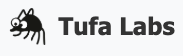

**Note**: this notebook is a more readable version of the notebook that scored our milestone-winning 1.21; unfortunately, we haven't had the same lucky result with this one. The original one is also shared here, but using it is not recommended: https://www.kaggle.com/code/jeroencottaar/taaf-duck-harness-kaggle

**Note**: if you make a copy of this notebook, you will have to manually select the proper GPU (RTX Pro 6000).

Link to writeup explaining what's going on here: https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3/discussion/717133

Link to Machine Learning Street Talk interview by Tim Scarfe about this duck harness: https://x.com/MLStreetTalk/status/2072326433922297975?s=20

This notebook executes the ARC-AGI-3 solver written by the Tufa Labs team; in alphabetical order: Harold Bessis, Jeroen Cottaar, Isaiah Pressman, Andries Smit, Michal Tesnar, and Stefano Viel.

You will only find infrastructure and diagnostics in this notebook; the actual solver code is in an attached dataset. See our writeup on the competition forum to learn more about that the solver actually does.

It installs the ARC runtime from the competition wheelhouse, makes the bundled source
snapshot importable, runs any solver setup commands, loads the pickled benchmark, plays the
competition games, and writes results to `/kaggle/working`. Diagnostics are minimised during
a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`) and kept full otherwise.

## 1. Environment and submission mode

Detect whether this is a real competition rerun (which minimises diagnostics), set the
framework's environment flags, and put the CUDA libraries on the linker path.

In [ ]:
import json
import os
import pickle
import subprocess
import sys
import sysconfig
import time
from datetime import datetime, timedelta
from pathlib import Path
from urllib.request import urlopen

# True only inside a real competition rerun; switches diagnostics + soft deadline.
TRUE_SUBMISSION = os.environ.get("KAGGLE_IS_COMPETITION_RERUN", "").strip().lower() in {"1", "true"}
NOTEBOOK_START_EPOCH = time.time()

# Non-interactive matplotlib backend: diagnostics render plots with no display attached.
os.environ["MPLBACKEND"] = "Agg"
# Marks the run as a (real or emulated) submission so the framework + solver can adjust.
os.environ["TAAF_RUN_AS_SUBMISSION"] = "1" if TRUE_SUBMISSION else "0"
# Skip periodic JSON/HTML diagnostics and per-frame logging for every run.
os.environ["TAAF_MINIMAL_DIAGNOSTICS"] = "1"

# Apply the measured vLLM winner before any serving setup command runs.
PUBLIC25_VLLM_PROFILE_NAME = 'kv5-bf16-mtp3-c8-cg32'
PUBLIC25_VLLM_PROFILE_ENV = {
    "TAAF_VLLM_ENABLE_PREFIX_CACHING": "0",
    "TAAF_VLLM_KV_CACHE_DTYPE": "auto",
    "TAAF_VLLM_KV_CACHE_MEMORY_BYTES": "5368709120",
    "TAAF_VLLM_MAX_CUDAGRAPH_CAPTURE_SIZE": "32",
    "TAAF_VLLM_MAX_NUM_BATCHED_TOKENS": "8192",
    "TAAF_VLLM_MAX_NUM_SEQS": "8",
    "TAAF_VLLM_MTP_TOKENS": "3",
    "TAAF_VLLM_OMP_THREADS": "1"
}
for key, value in PUBLIC25_VLLM_PROFILE_ENV.items():
    os.environ[key] = value
print(
    f'PUBLIC25_VLLM_PROFILE name={PUBLIC25_VLLM_PROFILE_NAME} '
    f'env={json.dumps(PUBLIC25_VLLM_PROFILE_ENV, sort_keys=True)}',
    flush=True,
)
# Pin arc_agi's cached level_reset_only before its client is built (RESET keeps the level).
os.environ["ONLY_RESET_LEVELS"] = "true"

# Prepend the CUDA toolkit to the linker path (it is off it on Kaggle GPU images) so the
# solver's GPU libraries (e.g. vllm / torch) can link against libcuda.
cuda_library_path = "/usr/local/nvidia/lib64"
os.environ["LIBRARY_PATH"] = os.pathsep.join(
    entry for entry in [cuda_library_path, *os.environ.get("LIBRARY_PATH", "").split(os.pathsep)] if entry
)

# Everything the run produces is written here.
WORKING_DIR = Path("/kaggle/working")
WORKING_DIR.mkdir(parents=True, exist_ok=True)
print(f"taaf.kaggle: TRUE_SUBMISSION={TRUE_SUBMISSION}")

## 2. Install the ARC runtime

Install `arc-agi` from the offline competition wheelhouse (the Kaggle submission environment
has no internet).

In [ ]:
# Install the ARC runtime from the bundled competition wheels.
# Quiet: stdout is discarded; stderr (and a non-zero exit) still surface real failures.
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--no-index",
        "--no-warn-conflicts",
        "--disable-pip-version-check",
        "--find-links",
        "/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels",
        "arc-agi",
    ],
    stdout=subprocess.DEVNULL,
)

## 3. Locate the source bundle

Find the uploaded TAAF source dataset by its marker file, and record where Kaggle mounted
every attached input so setup commands and the solver can find them.

In [ ]:
# Kaggle inputs attached to this notebook, plus bookkeeping paths used below.
DATASET_SOURCES = ["keithtyser/duck-qwen38-nvfp4-mtp-vllm-smoke-v1", "keithtyser/qwen38-flash-next-vllm-nvfp4-runtime-v1"]
KERNEL_SOURCES = []
DATASET_BUNDLE_MARKER = "taaf-kaggle-bundle.json"
SETUP_ENV_PATH = WORKING_DIR / "taaf_setup_env.json"


# Locate the source dataset by its marker file rather than a fixed mount path.
def _find_bundle_dir() -> Path:
    for marker in Path("/kaggle/input").rglob(DATASET_BUNDLE_MARKER):
        return marker.parent
    raise RuntimeError("TAAF source bundle not found under /kaggle/input.")


# Kaggle mounts a dataset at /kaggle/input/<slug> or /kaggle/input/datasets/<owner>/<slug>
# (depending on owner / slug collisions), so probe both and use whichever exists. Utility
# scripts mount under /kaggle/usr/lib/notebooks/<owner>/<slug>.
def _dataset_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/input") / slug, Path("/kaggle/input/datasets") / owner / slug]


def _kernel_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/usr/lib/notebooks") / owner / slug]


def _first_existing(candidates: list[Path]) -> Path | None:
    return next((c for c in candidates if c.exists()), None)


BUNDLE_DIR = _find_bundle_dir()
print(f"taaf.kaggle: source bundle = {BUNDLE_DIR}")

# Map each attached input to where Kaggle actually mounted it (the source bundle is index 0).
kaggle_input_paths: dict[str, str] = {}
for i, ref in enumerate(DATASET_SOURCES):
    candidates = _dataset_mount_candidates(ref)
    resolved = BUNDLE_DIR if i == 0 else _first_existing(candidates)
    kaggle_input_paths[ref] = str(resolved or candidates[0])
for ref in KERNEL_SOURCES:
    candidates = _kernel_mount_candidates(ref)
    kaggle_input_paths[ref] = str(_first_existing(candidates) or candidates[0])

# Published to setup commands and the solver via the environment:
setup_env = {
    # JSON {ref: mount_path} so they can locate every attached dataset / utility script.
    "TAAF_KAGGLE_INPUT_PATHS": json.dumps(kaggle_input_paths, sort_keys=True),
    # The attached dataset refs in order (index 0 is this source bundle).
    "TAAF_KAGGLE_DATASET_SOURCES": json.dumps(DATASET_SOURCES),
    # The attached utility-script / kernel refs.
    "TAAF_KAGGLE_KERNEL_SOURCES": json.dumps(KERNEL_SOURCES),
}
os.environ.update(setup_env)
SETUP_ENV_PATH.write_text(json.dumps(setup_env, indent=2, sort_keys=True) + "\n")
print(f"taaf.kaggle: input paths = {setup_env['TAAF_KAGGLE_INPUT_PATHS']}")

## 4. Import the bundled source and run solver setup

Put the snapshotted repositories on the path (this process and any child processes), then run
the solver's setup commands â€” installing wheels, fetching model weights, and so on.

In [ ]:
# Each bundled repo exposes its importable tree at <repo>/src or <repo>.
def _source_path_entries(bundle_dir: Path) -> list:
    entries = []
    for repo in sorted((bundle_dir / "src").iterdir(), reverse=True):
        for candidate in (repo / "src", repo):
            if candidate.is_dir():
                entries.append(candidate)
    return entries


# Environment handed to each setup command (paths + any keys it has persisted).
def _command_env() -> dict:
    env = os.environ.copy()
    # "$PYTHON" in a command resolves to this notebook's interpreter.
    env["PYTHON"] = sys.executable
    # Absolute path to the mounted source bundle.
    env["TAAF_KAGGLE_BUNDLE_DIR"] = str(BUNDLE_DIR)
    # The writable /kaggle/working directory.
    env["TAAF_KAGGLE_WORKING_DIR"] = str(WORKING_DIR)
    # A command writes a JSON object here to persist env keys to later commands + the run.
    env["TAAF_KAGGLE_SETUP_ENV"] = str(SETUP_ENV_PATH)
    env.update({str(k): str(v) for k, v in json.loads(SETUP_ENV_PATH.read_text()).items()})
    return env


# Make the bundled repos importable here (sys.path) and in child processes (.pth).
source_entries = _source_path_entries(BUNDLE_DIR)
for entry in source_entries:
    sys.path.insert(0, str(entry))
pth_path = Path(sysconfig.get_paths()["purelib"]) / "taaf_kaggle_sources.pth"
pth_path.write_text("".join(f"{entry}\n" for entry in source_entries))
print(f"taaf.kaggle: wrote {pth_path} ({len(source_entries)} source roots)")

# Solver setup commands (wheels, vLLM server startup, ...) run before the benchmark loads.
env = _command_env()
for command in json.loads((BUNDLE_DIR / "setup_commands.json").read_text()):
    print(f"taaf.kaggle: setup command: {command}", flush=True)
    subprocess.run(command, shell=True, check=True, cwd=WORKING_DIR, env=env)
    # Re-read in case the command persisted new env keys.
    env = _command_env()
    os.environ.update(env)

# Honour any PYTHONPATH a setup command exported.
for entry in reversed([e for e in os.environ.get("PYTHONPATH", "").split(os.pathsep) if e]):
    if entry not in sys.path:
        sys.path.insert(0, entry)

## 5. Load the benchmark

Unpickle the deployment target and the benchmark, stamping the real submission state onto the
target and pointing the benchmark's outputs at the Kaggle working directory.

In [ ]:
# Restore the deployment target and record the real submission state on it.
with open(BUNDLE_DIR / "deploy_target.pkl", "rb") as file:
    target = pickle.load(file)
target.actual_run_as_submission = TRUE_SUBMISSION
target.is_competition_rerun = TRUE_SUBMISSION

# Restore the benchmark and point its outputs at the Kaggle working dir.
with open(BUNDLE_DIR / "benchmark_initial.pkl", "rb") as file:
    bm = pickle.load(file)
bm.job_dir = WORKING_DIR

## 6. Customization hook

Optional: tweak `bm`, `bm.games`, or `bm.solver` here before the run starts â€” the safe place
for one-off experiments once the deployed bundle has loaded.

In [ ]:
# Exact public-25 and competition settings.
# arc3: the rerun keeps their measured 7920 s; a save run is capped so our first
# end-to-end test of this serving stack is affordable.
bm.solver.max_runtime_s_per_game = 7920.0 if TRUE_SUBMISSION else 1200.0
bm.solver.analyzer_timeout = 900.0
bm.solver.concurrency = 28
bm.solver.max_actions_per_game = None
bm.solver.save_request_logs = False
if float(getattr(target, 'max_runtime_s', 0.0) or 0.0) != 32400.0:
    raise RuntimeError(
        f'Expected the 32400-second notebook budget, got {target.max_runtime_s!r}.'
    )
print(
    f'PUBLIC25_SETTINGS budget_s={bm.solver.max_runtime_s_per_game} '
    f'concurrency={bm.solver.concurrency} analyzer_timeout={bm.solver.analyzer_timeout} '
    f'action_cap={bm.solver.max_actions_per_game} request_logs={bm.solver.save_request_logs}',
    flush=True,
)


In [ ]:
# arc3_batch: prompt-only predict-then-commit batching. Nothing else is touched.
#
# tool_agent.py:17 does `from inference.agent.prompts import PYTHON_ADDENDUM`, so the
# value is bound into tool_agent's namespace at import time; patching prompts.py alone
# would be a silent no-op. arc3_batch patches both bindings and then asserts against the
# string _build_system_prompt actually returns, so a miss fails the cell, not the run.
ARC3_BATCH_SOURCE = "\"\"\"arc3_batch: predict-then-commit action batching, as a PROMPT-ONLY change.\n\nWhy this and nothing else (consult/research_2026-09-19_next_jump.md):\n  fp4run1 executed 2.33 actions per charged model decision, 57% of them singletons, at\n  802 generated tokens per executed action. The harness never truncates a batch\n  (stopped_early 0, known_noop 0), so the short batches are the model's own choice --\n  steered by two lines in prompts.py that pull against the one line encouraging batching.\n  Folding an extra action into an existing decision is nearly free, so 2.33 -> ~6 is\n  ~2.5x the actions per game from the same token budget.\n\nExternally corroborated: DREAMTEAM (NVIDIA, arXiv 2605.09650) runs max-actions-per-step\n= 20 behind a commit-then-retrodict gate and reports 54.1 actions per solved level against\na baseline's 100.1; Reki (Milestone-1 2nd) returns 1-4 actions per turn.\n\nTHE PATCH TARGET MATTERS. tool_agent.py:17 does `from inference.agent.prompts import\nPYTHON_ADDENDUM`, so the value is bound into tool_agent's namespace at import time and\n_build_system_prompt (tool_agent.py:499) resolves it as a tool_agent global at call time.\nPatching prompts.PYTHON_ADDENDUM alone is a silent no-op. We patch both and then assert\nagainst the real _build_system_prompt output.\n\nNo harness behaviour is touched: no new mechanism, no gating code, no counters. The only\nthing that changes is the system prompt text.\n\"\"\"\nfrom __future__ import annotations\n\n# --- the three exact lines we rewrite (each must appear exactly once) -----------------\n\nOLD_SHORTEST = (\n    \"- Optimize for the shortest reliable sequence that advances the current goal as \"\n    \"described by your world model. If confidence is low, program a discriminating probe \"\n    \"and revise the world model from the result.\\n\"\n)\nNEW_SHORTEST = (\n    \"- Optimize for the fewest WASTED actions, not the fewest actions per turn. A ten-action \"\n    \"plan you can predict is worth far more than one action you must re-derive next turn. If \"\n    \"confidence is low, program a discriminating probe and revise the world model from the result.\\n\"\n)\n\n# \"After EVERY action, verify\" is a literal instruction to end the turn after one action.\n# The HUD warning itself is a real correctness guard, so it is kept -- moved into the\n# definition of the signature you compare frames on, instead of being a reason to stop.\nOLD_HUD = (\n    \"- After every action, verify whether gameplay objects changed or whether only a timer, \"\n    \"progress bar, or remaining-step bar moved. Do not treat HUD-only changes as evidence \"\n    \"that the move worked.\\n\"\n)\nNEW_HUD = (\n    \"- When you check whether an action worked, ignore HUD-only changes: a timer, progress bar \"\n    \"or remaining-step bar moving is not evidence that the move affected gameplay. Exclude \"\n    \"those rows from any signature you compare frames on.\\n\"\n)\n\n# Anchor: the existing line that already licenses loops. The protocol goes right after it.\nANCHOR_LOOPS = (\n    \"- You can also call `action(...)` multiple times in one Python snippet, including inside \"\n    \"loops. Each call updates the preloaded variables before execution continues.\\n\"\n)\nPROTOCOL = (\n    \"- ACTION BUDGET: reaching one turn of reasoning costs you thousands of tokens; extra actions \"\n    \"inside that same turn cost almost nothing. A turn that executes a single action throws the \"\n    \"turn away. Once you know what the controls do, plan a sequence and commit it.\\n\"\n    \"- PREDICT-THEN-COMMIT: when your world model can predict what the next few actions will do, \"\n    \"execute them in one snippet behind a prediction gate:\\n\"\n    \"      def sig(f):   # cheap board signature; exclude HUD rows\\n\"\n    \"          ...\\n\"\n    \"      plan = [(a1, expected_sig_1), (a2, expected_sig_2), ...]\\n\"\n    \"      for i, (a, expected) in enumerate(plan):\\n\"\n    \"          action([a])\\n\"\n    \"          if last_action_result.get('level_completed') or last_action_result.get('game_over'):\\n\"\n    \"              break\\n\"\n    \"          if sig(current_frame) != expected:\\n\"\n    \"              print('mismatch at step', i, 'expected', expected, 'got', sig(current_frame))\\n\"\n    \"              break        # the world model was wrong: stop here and re-plan next turn\\n\"\n    \"  A mismatch is the most valuable thing the turn can produce, so report where it happened and \"\n    \"what differed. A gated plan is safe: it stops itself the moment reality diverges.\\n\"\n    \"- Aim for 5-15 actions per turn once the controls are understood. Spend one- or two-action \"\n    \"turns only while you are still identifying what the controls do.\\n\"\n)\n\n\ndef build_addendum(current: str) -> str:\n    \"\"\"Apply the three edits to PYTHON_ADDENDUM, failing loudly on upstream drift.\"\"\"\n    for name, old in ((\"OLD_SHORTEST\", OLD_SHORTEST), (\"OLD_HUD\", OLD_HUD),\n                      (\"ANCHOR_LOOPS\", ANCHOR_LOOPS)):\n        n = current.count(old)\n        if n != 1:\n            raise RuntimeError(f\"arc3_batch: expected {name} exactly once in PYTHON_ADDENDUM, found {n}\")\n    out = current.replace(OLD_SHORTEST, NEW_SHORTEST)\n    out = out.replace(OLD_HUD, NEW_HUD)\n    out = out.replace(ANCHOR_LOOPS, ANCHOR_LOOPS + PROTOCOL)\n    return out\n\n\nMARKER = \"PREDICT-THEN-COMMIT\"\n\n\ndef install() -> dict:\n    \"\"\"Patch the system prompt in place. Idempotent; verifies against _build_system_prompt.\"\"\"\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    if MARKER in TA.PYTHON_ADDENDUM:\n        return {\"installed\": \"already\"}\n\n    before = len(TA.PYTHON_ADDENDUM)\n    new = build_addendum(TA.PYTHON_ADDENDUM)\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n\n    # The only proof that matters: the prompt the agent actually sends.\n    built = TA._build_system_prompt(tool_output_tokens=1024)\n    if MARKER not in built:\n        raise RuntimeError(\"arc3_batch: patch did not reach _build_system_prompt\")\n    for name, old in ((\"OLD_SHORTEST\", OLD_SHORTEST), (\"OLD_HUD\", OLD_HUD)):\n        if old in built:\n            raise RuntimeError(f\"arc3_batch: {name} still present in the built system prompt\")\n    return {\n        \"installed\": True,\n        \"addendum_chars\": len(new),\n        \"delta_chars\": len(new) - before,\n        \"system_prompt_chars\": len(built),\n    }\n"
Path('/kaggle/working/arc3_batch.py').write_text(ARC3_BATCH_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')

import importlib
import arc3_batch
arc3_batch = importlib.reload(arc3_batch)
print('arc3_batch:', arc3_batch.install(), flush=True)

from inference.agent import tool_agent as _ta
_built = _ta._build_system_prompt(tool_output_tokens=1024)
assert arc3_batch.MARKER in _built, 'arc3_batch did not reach the system prompt'
print('ARC3_BATCH_PROMPT chars=%d marker=%s' % (len(_built), arc3_batch.MARKER), flush=True)

# arc3_stall: loop/grind detection on top of arc3_batch. Harness-side tracking, because a
# model that is looping is by definition not noticing that it is looping.
ARC3_STALL_SOURCE = "\"\"\"arc3_stall: tell the agent when it is looping on a level it cannot clear.\n\nEvidence (depthrun1, 6 games x 3600 s). Duck clears every level it clears at or better\nthan human pace, then hits ONE level and grinds without ever clearing it -- 1.4-7.2x the\nhuman baseline, all six games ending `gave_up` still on that level. On the wall level the\naction mix collapses:\n\n    game  cleared-levels uniq_frac -> wall uniq_frac   most-repeated action on the wall\n    sb26            0.67 -> 0.16                       one click x19  of 133\n    vc33            0.24 -> 0.10                       one click x122 of 439\n    lp85            0.29 -> 0.12                       one click x30  of 83\n    re86            0.05 -> 0.02                       ACTION3  x104 of 368\n    ft09            0.67 -> 0.41\n\nvc33 clicked the same cell 122 times. That is a loop, and Duck's own no-op guard cannot\nsee it: the guard only blocks an action that left the board UNCHANGED in that exact state,\nand a looping action usually does change the board (it just changes it pointlessly, or\noscillates). Nothing anywhere else in the harness notices.\n\nWARNING FIRST, THEN RESET -- and the warning was refuted. stallrun2 ran the warn-only version\nover the same 6 games: it fired 100 warnings and moved the normalised loop metric\n(most-repeated action / wall actions) from 0.234 to 0.219, i.e. not at all. Levels went 19 ->\n23, but ALL of that was sb26 alone going 1 -> 7; without sb26 the run was net negative\n(23.33 vs 28.81 on the 6-game RHAE mean), and it had 42% MORE actions to work with. So the\nagent is not failing to notice that it is looping -- it cannot get out. That is the\npre-registered \"reset\" branch, and MODE now defaults to it: a stuck batch is replaced by a\nsingle RESET, which under ONLY_RESET_LEVELS rewinds THIS level only and keeps cleared levels\nand score. A RESET costs one action, against walls of 83-439.\n\nRETRACTION (2026-09-20). resetrun2 and resetrun3 did NOT test the reset. A safety gate that\nskipped the reset when \"RESET\" was absent from `valid_actions` suppressed 91 of 91 trips --\n`resets_issued: 0` in resetrun3's counters -- because `valid_actions` NEVER lists RESET; it is\ngameplay only. Every RESET in those runs' histories was the model's own: depthrun1, carrying no\nadd-on at all, already had 10 of them (1.7/run), the same rate as every other run. So all three\n\"stall\" runs measured the WARN branch, and their five-game means -- 23.33, 35.20, 37.46 against\na no-add-on 28.81 -- are one treatment measured three times. That spread IS the noise floor of\nthis 6-game probe, and the warning has no detectable effect. The gate is gone. Nothing below has\nbeen tested on Kaggle yet.\n\nBASELINE-FREE BY CONSTRUCTION. base_actions_per_level is None in submission mode\n(game_api.py:232-242), so nothing may compare against the human baseline -- it works on the\n25 public games and silently dies on the hidden set. The grind trigger therefore compares\nthe current level against the median of THAT GAME'S OWN cleared levels. depthrun1 shows the\nseparation is wide: cleared levels ran 4-80 actions, wall levels 83-439.\n\nHooks, and READ THIS BEFORE EDITING. The Kaggle FP4 stack does NOT ship the Duck revision\nin duck-study/taaf. Its bundle (keithtyser/duck-qwen38-nvfp4-mtp-vllm-smoke-v1, dated\n2026-08-31) carries an EARLIER tool_agent.py -- 89,299 bytes against the 108,927 in taaf --\nwith **no noop_guard.py at all**, no `_aggregate_action_batch_result`, and no per-action\nbatch walk: one `action([...])` call is one atomic step_env call. A first version of this\nmodule hooked `NoopGuard.observe` and died on Kaggle with\n`ImportError: cannot import name 'noop_guard' from 'inference.agent'` after 11 minutes of\nsetup. Pre-flight against duck-study/fp4src/ARC3-Inference, which is the shipped source.\n\nBoth hooks are plain methods on ToolAgent, and one ToolAgent plays one game, so per-instance\nstate is per-game state:\n  ToolAgent._normalize_python_actions  -> the actions about to run (stash them)\n  ToolAgent._compact_action_result     -> the level, and the payload the model reads\n`_serialized_runtime_state` and `_handle_action` are CLOSURES inside a method\n(tool_agent.py:1466, :1495 in the shipped file) and cannot be patched from outside.\n\"\"\"\nfrom __future__ import annotations\n\nimport os\nimport statistics\n\nREPEAT_N = int(os.environ.get(\"ARC3_STALL_REPEAT_N\", \"10\"))    # same action this often on one level\nWINDOW = int(os.environ.get(\"ARC3_STALL_WINDOW\", \"40\"))        # rolling window for the mix check\nUNIQ_FRAC = float(os.environ.get(\"ARC3_STALL_UNIQ_FRAC\", \"0.2\"))\nGRIND_MULT = float(os.environ.get(\"ARC3_STALL_GRIND_MULT\", \"3.0\"))\nGRIND_FLOOR = int(os.environ.get(\"ARC3_STALL_GRIND_FLOOR\", \"60\"))\nRENOTIFY_EVERY = int(os.environ.get(\"ARC3_STALL_RENOTIFY\", \"15\"))\n\n# Arming gate, applied to EVERY trigger. Without it the repeat rule fires during healthy\n# play on movement games, where pressing ACTION3 ten times in a row is just walking: the\n# depthrun1 replay warned re86 at action 13 and ar25 at 16 of levels they went on to CLEAR.\n# A warning that interrupts a working plan is worse than a late one, so nothing fires until\n# the level has already cost 3x this game's own cleared levels. At 2.0 the replay still\n# warned inside ar25's level 3 (80 actions against a median of 28) and vc33's level 3,\n# both of which were then CLEARED. 3.0 costs us the ar25 wall entirely and is still the\n# right trade: a late warning wastes actions, a wrong one derails a level being solved.\nMIN_ON_LEVEL = int(os.environ.get(\"ARC3_STALL_MIN_ON_LEVEL\", \"45\"))\n# \"warn\" tells the model it is stuck; \"reset\" replaces the stuck batch with a single RESET.\n# HIDDEN-SET VERDICT (2026-09-21), the only instrument that resolved this:\n#     batching only 3.04  |  + warn 3.37  |  + reset 2.84\n# Reset scored BELOW batching alone and 0.53 below warn -- the clearest separation we have on\n# the hidden set (~2.3 SE by a crude estimate). The 6-game probe ranked reset BEST (39.37); it\n# had the direction wrong. Default is therefore \"warn\". The best submission (56406950, 3.37) was\n# built with MODE=reset but every reset suppressed, so it behaved as warn; the Kaggle kernel\n# habanwer/arc3-duck-fp4-reset v3 is the exact artifact if byte-for-byte reproduction matters.\nMODE = os.environ.get(\"ARC3_STALL_MODE\", \"warn\").strip().lower()\nMAX_RESETS_PER_LEVEL = int(os.environ.get(\"ARC3_STALL_MAX_RESETS\", \"2\"))\n# Scope of that cap. \"level\" is the documented intent. \"game\" is what resetrun4 (v4) actually\n# ran: `resets` was only zeroed in __init__, never on a new level, so v4 allowed 2 resets per\n# GAME and suppressed 39 trips on later walls (resets_issued 10, resets_suppressed_cap 39).\n# Set ARC3_STALL_CAP_SCOPE=game to reproduce v4 exactly.\nCAP_SCOPE = os.environ.get(\"ARC3_STALL_CAP_SCOPE\", \"level\").strip().lower()\nARM_MULT = float(os.environ.get(\"ARC3_STALL_ARM_MULT\", \"3.0\"))\n\nSTATS = {\"levels_seen\": 0, \"trips\": 0, \"warnings_shown\": 0, \"resets_issued\": 0,\n         \"resets_suppressed_cap\": 0}\n\nclass _Tracker:\n    \"\"\"Per-ToolAgent state, and one ToolAgent plays one game.\"\"\"\n\n    def __init__(self) -> None:\n        self.level = None\n        self.counts: dict[str, int] = {}\n        self.window: list[str] = []\n        self.on_level = 0\n        self.cleared: list[int] = []      # actions spent on each level this game CLEARED\n        self.warned_at = 0\n        self.resets = 0\n\n    def _new_level(self, level) -> None:\n        if self.level is not None and self.on_level > 0:\n            # the level advanced, so the previous one was cleared. RESET keeps the level,\n            # so a reset cannot land here and pollute the baseline.\n            self.cleared.append(self.on_level)\n        self.level = level\n        self.counts = {}\n        self.window = []\n        self.on_level = 0\n        self.warned_at = 0\n        if CAP_SCOPE == \"level\":\n            self.resets = 0               # a new level gets its own reset budget\n        STATS[\"levels_seen\"] += 1\n\n    def observe(self, level, action_sig: str) -> None:\n        if level != self.level:\n            self._new_level(level)\n        self.on_level += 1\n        self.counts[action_sig] = self.counts.get(action_sig, 0) + 1\n        self.window.append(action_sig)\n        if len(self.window) > WINDOW:\n            del self.window[0]\n\n    def reason(self) -> str:\n        \"\"\"Why this level looks stuck, or \"\". Pure: no counters, no state.\"\"\"\n        arm = MIN_ON_LEVEL\n        if self.cleared:\n            arm = max(arm, ARM_MULT * statistics.median(self.cleared))\n        if self.on_level < arm:\n            return \"\"\n\n        worst_sig, worst_n = \"\", 0\n        for sig, n in self.counts.items():\n            if n > worst_n:\n                worst_sig, worst_n = sig, n\n\n        if worst_n >= REPEAT_N:\n            return f\"you have executed {worst_sig} {worst_n} times on this level\"\n        if len(self.window) >= WINDOW and len(set(self.window)) / len(self.window) < UNIQ_FRAC:\n            return (f\"your last {len(self.window)} actions used only \"\n                    f\"{len(set(self.window))} distinct actions\")\n        if self.cleared:\n            budget = max(GRIND_FLOOR, GRIND_MULT * statistics.median(self.cleared))\n            if self.on_level >= budget:\n                return (f\"you have spent {self.on_level} actions on this level, against a median \"\n                        f\"of {statistics.median(self.cleared):.0f} on the levels you already cleared\")\n        elif self.on_level >= max(GRIND_FLOOR, REPEAT_N * 6):\n            return f\"you have spent {self.on_level} actions on this level without clearing it\"\n        return \"\"\n\n    def armed(self) -> str:\n        \"\"\"reason(), rate-limited to once every RENOTIFY_EVERY actions on this level.\"\"\"\n        r = self.reason()\n        if not r:\n            return \"\"\n        if self.warned_at and self.on_level - self.warned_at < RENOTIFY_EVERY:\n            return \"\"\n        self.warned_at = self.on_level\n        STATS[\"trips\"] += 1\n        return r\n\n    def on_reset(self) -> None:\n        \"\"\"A RESET keeps the level (ONLY_RESET_LEVELS), so _new_level never fires. Clear the\n        per-level counters by hand so the fresh attempt gets a full arming budget, and keep\n        `cleared` -- that is the baseline and a reset must not pollute it.\"\"\"\n        self.resets += 1\n        self.counts = {}\n        self.window = []\n        self.on_level = 0\n        self.warned_at = 0\n\n    def warning(self) -> \"str | None\":\n        r = self.armed()\n        if not r:\n            return None\n        STATS[\"warnings_shown\"] += 1\n        return (\n            f\"STUCK: {r}, and the level has not advanced. Repeating it again will not clear \"\n            \"the level. Your current hypothesis about this level is wrong. Stop executing the plan \"\n            \"you are on, re-read the board from scratch, and form a DIFFERENT hypothesis about what \"\n            \"this level wants -- a different object to act on, a different mechanic, or a different \"\n            \"goal than the one you assumed.\"\n        )\n\n\n_ORIG_NORMALIZE = None\n_ORIG_COMPACT = None\n\n\ndef _tracker(agent) -> \"_Tracker\":\n    t = getattr(agent, \"_arc3_tracker\", None)\n    if t is None:\n        t = _Tracker()\n        try:\n            agent._arc3_tracker = t\n        except Exception:\n            pass\n    return t\n\n\ndef _sig(action) -> str:\n    \"\"\"Signature of one action. Handles BOTH shapes: the tool_agent normalized form\n    {\"action\": NAME, \"row\": r, \"col\": c} (Duck speaks row/col and raises on x/y), and the\n    engine/benchmark form {\"id\": NAME, \"data\": {\"x\": .., \"y\": ..}} used by replays. Getting\n    this wrong collapses every click to one signature and fires the repeat rule on healthy\n    play -- the pre-flight caught exactly that.\n    \"\"\"\n    if not isinstance(action, dict):\n        return str(action)\n    name = str(action.get(\"action\") or action.get(\"id\") or \"?\")\n    if \"row\" in action or \"col\" in action:\n        return f\"{name}:{action.get('row')},{action.get('col')}\"\n    data = action.get(\"data\")\n    if isinstance(data, dict) and data:\n        return f\"{name}:{data.get('x')},{data.get('y')}\"\n    return name\n\n\nRESET_NOTE = (\n    \"LEVEL RESET BY THE RUNNER. {reason}, and the level had not advanced, so your batch was \"\n    \"replaced with a single RESET. The level has restarted from its initial state and your \"\n    \"score and cleared levels are untouched -- only this level was rewound. Whatever you were \"\n    \"about to do would have continued a plan that has already failed {n} time(s) here. Do not \"\n    \"replay it. Re-read the board from the fresh start and form a DIFFERENT hypothesis about \"\n    \"what this level wants: a different object to act on, a different mechanic, or a different \"\n    \"goal than the one you assumed.\"\n)\n\n\ndef _maybe_reset(agent, actions):\n    \"\"\"Replace a stuck batch with one RESET. Returns the batch to execute.\"\"\"\n    if not isinstance(actions, list) or not actions:\n        return actions\n    t = _tracker(agent)\n    if len(actions) == 1 and str(actions[0].get(\"action\", \"\")).upper() == \"RESET\":\n        return actions                      # the model reset on its own; leave it alone\n    reason = t.armed()\n    if not reason:\n        return actions\n    if t.resets >= MAX_RESETS_PER_LEVEL:\n        STATS[\"resets_suppressed_cap\"] += 1\n        _PENDING[id(agent)] = _warn_text(reason)\n        return actions                      # already rewound this level twice; just warn\n    # NO valid_actions GATE. `valid_actions` NEVER contains RESET -- measured in resetrun3's\n    # own prompts, the list is gameplay only (UP/DOWN/LEFT/RIGHT/SPACE/MOUSE/ACTION7). RESET is\n    # always executable regardless: the model issued 10-23 of its own per run in every run we\n    # have, including depthrun1, which carried no add-on at all. The gate that used to live here\n    # suppressed 91 of 91 resets in resetrun3 and silently turned the reset branch back into the\n    # warn branch, which is why resetrun2/resetrun3 measured warn and not reset. Do not re-add it.\n    STATS[\"resets_issued\"] += 1\n    _PENDING[id(agent)] = RESET_NOTE.format(reason=reason[0].upper() + reason[1:], n=t.resets + 1)\n    t.on_reset()\n    return [{\"action\": \"RESET\"}]\n\n\ndef _warn_text(reason: str) -> str:\n    STATS[\"warnings_shown\"] += 1\n    return (\n        f\"STUCK: {reason}, and the level has not advanced. Repeating it again will not clear \"\n        \"the level. Your current hypothesis about this level is wrong. Stop executing the plan \"\n        \"you are on, re-read the board from scratch, and form a DIFFERENT hypothesis about what \"\n        \"this level wants -- a different object to act on, a different mechanic, or a different \"\n        \"goal than the one you assumed.\"\n    )\n\n\n_PENDING: dict = {}\n\n\ndef install() -> dict:\n    \"\"\"Patch the two ToolAgent methods the shipped revision actually has. Idempotent.\"\"\"\n    global _ORIG_NORMALIZE, _ORIG_COMPACT\n    from inference.agent import tool_agent as TA\n\n    if getattr(TA.ToolAgent._compact_action_result, \"_arc3_stall\", False):\n        return {\"installed\": \"already\"}\n\n    _ORIG_NORMALIZE = TA.ToolAgent._normalize_python_actions\n    _ORIG_COMPACT = TA.ToolAgent._compact_action_result\n\n    def normalize(self, value):\n        out = _ORIG_NORMALIZE(self, value)\n        try:\n            if MODE == \"reset\":\n                out = _maybe_reset(self, out)\n            self._arc3_pending = list(out) if isinstance(out, list) else []\n        except Exception:\n            pass\n        return out\n\n    normalize._arc3_stall = True\n    TA.ToolAgent._normalize_python_actions = normalize\n\n    def compact(self, payload):\n        out = _ORIG_COMPACT(self, payload)\n        try:\n            pending = getattr(self, \"_arc3_pending\", None) or []\n            self._arc3_pending = []\n            if pending and isinstance(out, dict) and out.get(\"executed\"):\n                t = _tracker(self)\n                level = out.get(\"level\")\n                msg = None\n                for action in pending:\n                    t.observe(level, _sig(action))\n                    if MODE != \"reset\":\n                        msg = t.warning() or msg\n                queued = _PENDING.pop(id(self), None)\n                if queued or msg:\n                    out[\"stuck_warning\"] = queued or msg\n        except Exception:\n            pass   # a counter must never break a run\n        return out\n\n    compact._arc3_stall = True\n    TA.ToolAgent._compact_action_result = compact\n    return {\"installed\": True, \"mode\": MODE, \"max_resets\": MAX_RESETS_PER_LEVEL,\n            \"cap_scope\": CAP_SCOPE,\n            \"repeat_n\": REPEAT_N, \"window\": WINDOW, \"uniq_frac\": UNIQ_FRAC,\n            \"grind_mult\": GRIND_MULT, \"grind_floor\": GRIND_FLOOR,\n            \"min_on_level\": MIN_ON_LEVEL, \"arm_mult\": ARM_MULT}\n\n\nPROMPT_LINE = (\n    \"- `last_action_result` may carry a `stuck_warning` from the runner. It means this level has \"\n    \"already cost far more actions than the levels you cleared, and that you have been repeating \"\n    \"yourself. Treat it as decisive: your hypothesis about this level is wrong. If it says the \"\n    \"level was RESET, the board is back at this level's initial state, your cleared levels and \"\n    \"score are intact, and the plan you were running has been discarded -- do not replay it. \"\n    \"Re-read the board from scratch and form a different hypothesis about what the level wants \"\n    \"before acting again.\\n\"\n)\n\n\ndef install_prompt() -> dict:\n    \"\"\"Tell the model what a stuck_warning means. Same binding trap as arc3_batch.\"\"\"\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    if \"stuck_warning\" in TA.PYTHON_ADDENDUM:\n        return {\"installed\": \"already\"}\n    new = TA.PYTHON_ADDENDUM + PROMPT_LINE\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n    if \"stuck_warning\" not in TA._build_system_prompt(tool_output_tokens=1024):\n        raise RuntimeError(\"arc3_stall: prompt line did not reach _build_system_prompt\")\n    return {\"installed\": True}\n"
Path('/kaggle/working/arc3_stall.py').write_text(ARC3_STALL_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')
# /kaggle/working was already on sys.path from the arc3_batch cell, so its FileFinder has a
# cached directory listing that predates this write. Without this, `import arc3_stall` raises
# ModuleNotFoundError for a file that is sitting right there -- it did, on reset run v1.
importlib.invalidate_caches()

import arc3_stall
arc3_stall = importlib.reload(arc3_stall)
print('arc3_stall:', arc3_stall.install(), flush=True)
print('arc3_stall prompt:', arc3_stall.install_prompt(), flush=True)

_built2 = _ta._build_system_prompt(tool_output_tokens=1024)
assert 'stuck_warning' in _built2, 'arc3_stall prompt line did not reach the system prompt'
assert arc3_batch.MARKER in _built2, 'arc3_batch protocol lost'
print('ARC3_STALL_READY chars=%d' % len(_built2), flush=True)

# arc3_ledger: hypothesis bookkeeping after a failed attempt (prompt-only).
assert arc3_stall.MODE == 'warn', 'stall must be in warn mode -- the 3.37 configuration'
ARC3_LEDGER_SOURCE = "\"\"\"arc3_ledger: hypothesis bookkeeping after a failed attempt. PROMPT-ONLY.\n\nEvidence (consult/walls_2026-09-21.md). On sb26 level 2 a run that solved it in 3 turns and a\nrun that failed after 153 actions perceived the board identically and shared the same, correct\nmodel of the controls. They differed in ONE assumption about the goal: the winner read the green\nconnector as a path, the loser used reading order. The loser's attempt failed on its second turn,\nand it then spent 57 turns re-investigating controls it had already confirmed and never tried\nthe other ordering. Both runs that passed that level went on to level 8.\n\nSo the change is aimed at what happens AFTER a failed attempt: keep what was observed, blame the\nassumption the attempt rested on, and try its alternatives. It tells the model something and\nleaves the choice to it -- the style of both changes that helped (batching 2.49 -> 3.04, stuck\nwarning 3.04 -> 3.37), unlike the one that overrode it (forced reset, 2.84).\n\nSame binding trap as arc3_batch: tool_agent does `from inference.agent.prompts import\nPYTHON_ADDENDUM`, so both bindings are patched and the result is asserted against\n_build_system_prompt, the string the agent actually sends.\n\"\"\"\nfrom __future__ import annotations\n\nMARKER = \"WHEN AN ATTEMPT FAILS\"\n\nLEDGER = (\n    \"- WHEN AN ATTEMPT FAILS -- your plan ran to the end, or you submitted, and the level did not \"\n    \"complete -- do not re-investigate what you have already confirmed by direct observation. \"\n    \"Write two short lists in your reasoning. CONFIRMED: facts you have actually seen happen \"\n    \"(what a control does, what an object is). ASSUMED: the specific guess this attempt depended \"\n    \"on (the order things go in, which object is the target, how pieces are grouped, what the \"\n    \"goal state looks like). The failure is evidence about the ASSUMED list, not the CONFIRMED \"\n    \"one. List the few other readings of that assumption and try the cheapest untried one next. \"\n    \"Reopen a confirmed fact only if a new observation contradicts it.\\n\"\n)\n\n\ndef install() -> dict:\n    \"\"\"Append the ledger rule to PYTHON_ADDENDUM. Idempotent; verified against the real prompt.\"\"\"\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    if MARKER in TA.PYTHON_ADDENDUM:\n        return {\"installed\": \"already\"}\n    before = len(TA.PYTHON_ADDENDUM)\n    new = TA.PYTHON_ADDENDUM + LEDGER\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n    built = TA._build_system_prompt(tool_output_tokens=1024)\n    if MARKER not in built:\n        raise RuntimeError(\"arc3_ledger: rule did not reach _build_system_prompt\")\n    return {\"installed\": True, \"delta_chars\": len(new) - before, \"system_prompt_chars\": len(built)}\n"
Path('/kaggle/working/arc3_ledger.py').write_text(ARC3_LEDGER_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')
importlib.invalidate_caches()
import arc3_ledger
arc3_ledger = importlib.reload(arc3_ledger)
print('arc3_ledger:', arc3_ledger.install(), flush=True)
_built3 = _ta._build_system_prompt(tool_output_tokens=1024)
assert arc3_ledger.MARKER in _built3, 'arc3_ledger did not reach the system prompt'
assert arc3_batch.MARKER in _built3 and 'stuck_warning' in _built3, 'an earlier patch was lost'
print('ARC3_LEDGER_READY chars=%d' % len(_built3), flush=True)
# arc3_select: a highlight-only click is a selection. PROMPT-ONLY.
# Local arcade frame sb26-7fbdac44 seed 0 (2026-09-22), 44 actions, level stayed 0/8.
# Not a Kaggle score. A click on a solid piece changed only a white border. The next
# click on a gray mark turned that mark into the selected color. ACTION5 flipped one
# cell of the full-width bar and placed nothing. The blank center of the red frame
# and the top outlines changed nothing. MODE stays warn.
ARC3_SELECT_SOURCE = "\"\"\"arc3_select: a highlight-only click is a selection. PROMPT-ONLY.\n\nLocal arcade, sb26-7fbdac44, seed 0. Not a measured RHAE. The opening frame shows the\nsame colors twice: outlines in one left-to-right order, solid pieces in another, plus\nempty gray marks. Clicking a solid changed only a border around it. Clicking an empty\nmark after that turned the mark into the selected color. A click in the blank center of\nan outline changed nothing. ACTION5 changed one cell of a full-width bar and did not\nplace a piece.\n\nSame binding trap as arc3_batch: tool_agent binds PYTHON_ADDENDUM at import, so both\nbindings are patched and the result is asserted against _build_system_prompt.\n\"\"\"\nfrom __future__ import annotations\n\nMARKER = \"SELECT THEN PLACE\"\n\nRULE = (\n    \"- SELECT THEN PLACE: a click that changes only a border around the object you hit \"\n    \"has selected it and has not moved anything. Do not end the turn on a selection, and \"\n    \"do not read an unchanged board as proof the control does nothing. In the same snippet, \"\n    \"click the empty mark you want that object to fill and predict that the mark takes the \"\n    \"object's color. If it does not, stop and re-plan. Click a pixel of the object, not the \"\n    \"blank center of an outline. When the same colors appear once as outlines and once as \"\n    \"solid pieces, the outline order is one hypothesis for the goal; the order the solids \"\n    \"sit in is only their current position.\\n\"\n)\n\n\ndef install() -> dict:\n    \"\"\"Append the select-then-place rule. Idempotent; verified against the real prompt.\"\"\"\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    if MARKER in TA.PYTHON_ADDENDUM:\n        return {\"installed\": \"already\"}\n    before = len(TA.PYTHON_ADDENDUM)\n    new = TA.PYTHON_ADDENDUM + RULE\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n    built = TA._build_system_prompt(tool_output_tokens=1024)\n    if MARKER not in built:\n        raise RuntimeError(\"arc3_select: rule did not reach _build_system_prompt\")\n    return {\"installed\": True, \"delta_chars\": len(new) - before, \"system_prompt_chars\": len(built)}\n"
Path('/kaggle/working/arc3_select.py').write_text(ARC3_SELECT_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')
importlib.invalidate_caches()
import arc3_select
arc3_select = importlib.reload(arc3_select)
print('arc3_select:', arc3_select.install(), flush=True)
_built4 = _ta._build_system_prompt(tool_output_tokens=1024)
assert 'SELECT THEN PLACE' in _built4, 'arc3_select did not reach the system prompt'
assert arc3_ledger.MARKER in _built4 and 'stuck_warning' in _built4 and arc3_batch.MARKER in _built4, 'an earlier patch was lost'
assert arc3_stall.MODE == 'warn', 'stall must stay in warn mode'
print('ARC3_SELECT_READY chars=%d' % len(_built4), flush=True)
# arc3_path: a join is the order of the marks. PROMPT-ONLY.
# Local arcade sb26-7fbdac44 seed 0 (2026-09-22). Not a Kaggle score.
# Connector frame: upper-then-lower submit stayed on the level. Walking the
# line (marks before the join, the joined marks, the marks after it) and
# submitting advanced. The next frame has two joins; the same walk advanced.
# 40 actions, level index 3/8, NOT_FINISHED. MODE stays warn.
ARC3_PATH_SOURCE = '"""arc3_path: a join is the order of the marks. PROMPT-ONLY.\n\nLocal arcade, sb26-7fbdac44, seed 0. Not a measured RHAE.\nOn the frame with two boxes of marks joined by a green line, placing the\noutline colors across the upper marks and only then the lower marks, then\nsubmitting, left the level unchanged. Walking the line advanced it: marks\nbefore the join, the joined marks left to right, then the marks after the\njoin. On the next frame a row of marks is interrupted by a green block and\na blue block, each above a same-colored box. The same walk, one join at a\ntime, advanced on submit.\n\nSame binding trap as arc3_batch: tool_agent binds PYTHON_ADDENDUM at import,\nso both bindings are patched and the result is asserted against\n_build_system_prompt.\n"""\nfrom __future__ import annotations\n\nMARKER = "PATH BEFORE READING ORDER"\n\nRULE = (\n    "- PATH BEFORE READING ORDER: read the outline left to right as the color "\n    "sequence, and choose the mark order separately. When a line or a colored "\n    "block joins a row of empty marks to another group of marks, walk the marks "\n    "in path order. Marks already passed, then that group\'s marks left to right, "\n    "then the marks on the far side of the join. Do this at every join from left "\n    "to right. Place color 1 on the first mark of the walk, color 2 on the next, "\n    "and so on, then submit. The other order, every upper mark left to right and "\n    "only then the lower marks, is the fallback, and only after a path submit "\n    "leaves the level unchanged. Do not spend those later turns re-testing a "\n    "control you have already seen work.\\n"\n)\n\n\ndef install() -> dict:\n    """Append the path rule. Idempotent; verified against the real prompt."""\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    if MARKER in TA.PYTHON_ADDENDUM:\n        return {"installed": "already"}\n    before = len(TA.PYTHON_ADDENDUM)\n    new = TA.PYTHON_ADDENDUM + RULE\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n    built = TA._build_system_prompt(tool_output_tokens=1024)\n    if MARKER not in built:\n        raise RuntimeError("arc3_path: rule did not reach _build_system_prompt")\n    return {"installed": True, "delta_chars": len(new) - before, "system_prompt_chars": len(built)}\n'
Path('/kaggle/working/arc3_path.py').write_text(ARC3_PATH_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')
importlib.invalidate_caches()
import arc3_path
arc3_path = importlib.reload(arc3_path)
print('arc3_path:', arc3_path.install(), flush=True)
_built5 = _ta._build_system_prompt(tool_output_tokens=1024)
assert 'PATH BEFORE READING ORDER' in _built5, 'arc3_path did not reach the system prompt'
assert 'SELECT THEN PLACE' in _built5 and arc3_ledger.MARKER in _built5 and 'stuck_warning' in _built5 and arc3_batch.MARKER in _built5, 'an earlier patch was lost'
assert arc3_stall.MODE == 'warn', 'stall must stay in warn mode'
print('ARC3_PATH_READY chars=%d' % len(_built5), flush=True)
# arc3_map: the center picture is the grid. PROMPT-ONLY.
# Local arcade ft09-0d8bbf25 seed 0 (2026-09-22). Not a Kaggle score.
# Finished grids: light-gray in the center picture sits on blue, white sits on red.
# Painting the editable grid with that key advanced the level. 5 actions, level index 1/6.
# A same-day vc33 play cleared level 0 by the control that still moved. Not this rule.
# MODE stays warn.
ARC3_MAP_SOURCE = '"""arc3_map: the center picture is the grid. PROMPT-ONLY.\n\nLocal arcade, ft09-0d8bbf25, seed 0. Not a measured RHAE.\nTwo finished grids on the opening frame carry a picture in the center cell.\nLight-gray in that picture sits on blue cells, and white sits on red cells.\nThe unfinished grid\'s own picture, painted with that key, advanced the level.\nFlipping a cell and flipping it back both spend the bar.\n\nSame binding trap as arc3_batch: tool_agent binds PYTHON_ADDENDUM at import,\nso both bindings are patched and the result is asserted against\n_build_system_prompt.\n"""\nfrom __future__ import annotations\n\nMARKER = "CENTER MAP"\n\nRULE = (\n    "- CENTER MAP: a small picture in the center of a grid is a map of that grid. "\n    "Read the color key from a finished grid whose picture lines up with its cells: "\n    "each picture color corresponds to one cell color. Paint the editable grid\'s "\n    "other cells once so they match its own picture under that key. Do not paint "\n    "the center. Flipping a cell back does not refund the bar, so stop after one "\n    "pass. If the level stays, the picture was not the whole goal.\\n"\n)\n\n\ndef install() -> dict:\n    """Append the center-map rule. Idempotent; verified against the real prompt."""\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    if MARKER in TA.PYTHON_ADDENDUM:\n        return {"installed": "already"}\n    before = len(TA.PYTHON_ADDENDUM)\n    new = TA.PYTHON_ADDENDUM + RULE\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n    built = TA._build_system_prompt(tool_output_tokens=1024)\n    if MARKER not in built:\n        raise RuntimeError("arc3_map: rule did not reach _build_system_prompt")\n    return {"installed": True, "delta_chars": len(new) - before, "system_prompt_chars": len(built)}\n'
Path('/kaggle/working/arc3_map.py').write_text(ARC3_MAP_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')
importlib.invalidate_caches()
import arc3_map
arc3_map = importlib.reload(arc3_map)
print('arc3_map:', arc3_map.install(), flush=True)
_built6 = _ta._build_system_prompt(tool_output_tokens=1024)
assert 'CENTER MAP' in _built6, 'arc3_map did not reach the system prompt'
assert 'PATH BEFORE READING ORDER' in _built6 and 'SELECT THEN PLACE' in _built6 and arc3_ledger.MARKER in _built6 and 'stuck_warning' in _built6 and arc3_batch.MARKER in _built6, 'an earlier patch was lost'
assert arc3_stall.MODE == 'warn', 'stall must stay in warn mode'
print('ARC3_MAP_READY chars=%d' % len(_built6), flush=True)


## 7. Run the benchmark

In a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`), wait for the Kaggle gateway and
play the **live competition Arcade**. Otherwise â€” an interactive "Save & Run" â€” play the
competition's **bundled environment files offline**, with no gateway required, so the notebook
runs end-to-end without a submission. Teardown commands run afterward even if the run raises.

In [ ]:
# Build the live competition game list from the gateway's available environments.
def _competition_games():
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=os.environ["ARC_BASE_URL"],
        environments_dir="",
    )
    arcade = arc_agi.Arcade(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=spec.arc_base_url,
        environments_dir="",
    )
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError("Competition Arcade exposed zero environments.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# Build the offline game list from the competition's bundled environment files.
def _offline_games(env_dir: str):
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    arcade = arc_agi.Arcade(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError(f"No offline environments found under {env_dir}.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# The gateway can take a while to come up; poll until it answers.
def _wait_for_gateway(base_url: str, timeout_s: float = 600.0) -> None:
    deadline = time.monotonic() + timeout_s
    last_error = ""
    while time.monotonic() < deadline:
        try:
            with urlopen(f"{base_url}api/games", timeout=10) as response:
                if response.status < 500:
                    return
        except Exception as exc:
            last_error = repr(exc)
        time.sleep(5)
    raise RuntimeError(f"Kaggle gateway did not become ready: {last_error}")


# Skip pre-run display and git-status copies; the staged identity pins the run.

# arc_agi reads RECORDINGS_DIR and ARC_API_KEY from env (ArcadeSpec carries neither); operation
# mode, environments dir, and base url are all passed explicitly via the spec, so no env is needed.
os.environ.setdefault("RECORDINGS_DIR", str(WORKING_DIR / "server_recording"))

PUBLIC_GAME_IDS = tuple([
    "tn36-ef4dde99",
    "lf52-271a04aa",
    "cn04-2fe56bfb",
    "bp35-0a0ad940",
    "wa30-ee6fef47",
    "lp85-305b61c3",
    "r11l-495a7899",
    "tu93-0768757b",
    "sp80-589a99af",
    "m0r0-492f87ba",
    "vc33-5430563c",
    "ar25-0c556536",
    "ka59-38d34dbb",
    "sc25-635fd71a",
    "sk48-d8078629",
    "dc22-fdcac232",
    "cd82-fb555c5d",
    "ft09-0d8bbf25",
    "g50t-5849a774",
    "ls20-9607627b",
    "re86-8af5384d",
    "s5i5-18d95033",
    "sb26-7fbdac44",
    "su15-1944f8ab",
    "tr87-cd924810"
])

if TRUE_SUBMISSION:
    # Real submission: play the live competition Arcade served by the Kaggle gateway.
    os.environ.setdefault("ARC_API_KEY", "test-key-123")
    os.environ.setdefault("ARC_BASE_URL", "http://gateway:8001/")
    # The gateway boots asynchronously; wait before swapping in its game list.
    _wait_for_gateway(os.environ["ARC_BASE_URL"])
    bm.games = _competition_games()
else:
    # Interactive run: play the bundled competition environments offline (no gateway).
    # The competition's environment files ship alongside the wheelhouse in the competition dataset.
    competition_env_files = str(Path("/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels").parent / "environment_files")
    offline_games = _offline_games(competition_env_files)
    offline_by_id = {game.env_name: game for game in offline_games}
    if len(offline_by_id) != len(offline_games):
        raise RuntimeError('The offline public game list contains duplicate IDs.')
    missing = sorted(set(PUBLIC_GAME_IDS) - set(offline_by_id))
    extra = sorted(set(offline_by_id) - set(PUBLIC_GAME_IDS))
    if missing or extra:
        raise RuntimeError(
            f'Offline public game set changed; missing={missing}, extra={extra}.'
        )
    # arc3 depth probe: the 25-game integrity check above still runs, so upstream drift in the
    # offline set is still caught; we then play a 6-game subset long enough to reach level 2.
    DEPTH_PROBE_IDS = ["sb26-7fbdac44"]
    bm.games = [offline_by_id[game_id] for game_id in DEPTH_PROBE_IDS]
    if len(bm.games) != len(DEPTH_PROBE_IDS):
        raise RuntimeError(f'Expected {len(DEPTH_PROBE_IDS)} probe games, got {len(bm.games)}.')
    print(f'DEPTH_PROBE_SELECTION games={len(bm.games)} passes=1 cap_s=3600', flush=True)

bm.n_passes = 1
bm.game_weights = None

# Outside a real submission, stop ~10 min before the wall-clock budget for a graceful exit.
budget = float(getattr(target, "max_runtime_s", 0.0) or 0.0)
if budget <= 600.0:
    raise RuntimeError(f'Notebook budget is too small for the teardown reserve: {budget}.')
soft_end = datetime.fromtimestamp(NOTEBOOK_START_EPOCH) + timedelta(
    seconds=budget - 600.0
)

# Start recovery only after setup readiness and all run gates pass.
if str(BUNDLE_DIR) not in sys.path:
    sys.path.insert(0, str(BUNDLE_DIR))
import vllm_server_watchdog as vllm_watchdog

vllm_watchdog_setup = vllm_watchdog.load_setup(BUNDLE_DIR / 'serving_setup.py')
vllm_watchdog.start_background(
    vllm_watchdog_setup,
    vllm_watchdog.WatchdogConfig(
        interval_seconds=15.0,
        request_timeout_seconds=5,
        failure_threshold=4,
        max_restart_attempts=2,
    ),
)

# Play the benchmark; watchdog stop and teardown run even if it raises.
try:
    await bm.run(soft_end_time=soft_end, runtime_environment=target, minimal_diagnostics=True)
    bm._save_json()
    if not TRUE_SUBMISSION:
        # Kaggle Save & Run expects this valid placeholder after an offline run.
        # A real competition rerun uses the live gateway and never enters this branch.
        import pandas as pd

        pd.DataFrame(
            [["1_0", "1", True, 1]],
            columns=["row_id", "game_id", "end_of_game", "score"],
        ).to_parquet(WORKING_DIR / "submission.parquet", index=False)

        # Check terminal coverage, then call the frozen scorer once.
        # This path does not render HTML.
        public_runs = list(bm.game_runs)
        public_run_ids = [run.game_id for run in public_runs]
        # arc3: audit against the set we actually selected, and by MULTISET, not by order.
        # Upstream asserts exactly 25 ids in PUBLIC_GAME_IDS order, so a subset run dies here
        # (depthrun1) and so does a multi-pass run, where game_runs holds len(games)*n_passes
        # entries (resetrun2). Both played every game first and then lost the scorer call and
        # the COMPLETE status -- and an ERRORed version cannot be submitted.
        from collections import Counter as _ArcCounter
        _expected_ids = list(globals().get('DEPTH_PROBE_IDS') or PUBLIC_GAME_IDS)
        _passes = int(getattr(bm, 'n_passes', 1) or 1)
        _want = _ArcCounter({_gid: _passes for _gid in _expected_ids})
        if _ArcCounter(public_run_ids) != _want:
            raise RuntimeError(
                f'Public run coverage changed: count={len(public_runs)} ids={public_run_ids} '
                f'expected={_expected_ids} x{_passes} passes.'
            )
        unfinished = [
            (run.game_id, run.state, run.final_score)
            for run in public_runs
            if run.state not in {'won', 'gave_up', 'cancelled'}
            or run.final_score is None
        ]
        if unfinished:
            raise RuntimeError(f'Public runs did not finalize cleanly: {unfinished}.')
        crashed = [run.game_id for run in public_runs if run.state == 'crashed']
        if crashed:
            raise RuntimeError(f'Public runs crashed: {crashed}.')
        total_actions = sum(len(run.history) for run in public_runs)
        if total_actions <= 0:
            raise RuntimeError('Public runs produced no actions.')

        from inference.tools.eval import evaluate_runs, save_score_file

        score_summary = evaluate_runs([WORKING_DIR])
        score_path = save_score_file(
            score_summary,
            run_dirs=[WORKING_DIR],
            output_path=WORKING_DIR / "score.json",
        )
        if Path(score_path) != WORKING_DIR / 'score.json' or not Path(score_path).is_file():
            raise RuntimeError(f'Frozen scorer did not write score.json: {score_path}.')
        print(
            f'PUBLIC25_AUDIT runs=25 actions={total_actions} score_path={score_path}',
            flush=True,
        )
finally:
    try:
        vllm_watchdog.stop_background(timeout_seconds=15.0)
    finally:
        for command in json.loads((BUNDLE_DIR / "teardown_commands.json").read_text()):
            print(f"taaf.kaggle: teardown command: {command}", flush=True)
            subprocess.run(
                command,
                shell=True,
                check=False,
                cwd=WORKING_DIR,
                env=_command_env(),
                timeout=30.0,
            )


## 8. Show the diagnostics

A non-submission run writes `diagnostics.html` to `/kaggle/working`; it is rendered inline below
(and downloadable from the working directory). You should be able to click around through the links.

In [ ]:
# Minimal diagnostics are enabled; skip post-run HTML rendering.


In [ ]:
# Mechanism check only: did the model write CONFIRMED / ASSUMED ledgers after a failure?
import json as _json
import re as _re

_p = WORKING_DIR / 'benchmark.json'
if _p.exists():
    _b = _json.loads(_p.read_text(encoding='utf-8'))
    for _r in _b['game_runs']:
        print('ARC3_LEDGER_GAME', _r['game_id'], 'levels', _r['levels_completed'],
              'actions_per_level', _r['actions_per_level'], 'state', _r.get('state'), flush=True)
_hits = {'CONFIRMED': 0, 'ASSUMED': 0}
_turns = 0
for _t in sorted((WORKING_DIR / 'transcripts').glob('*.txt')) if (WORKING_DIR / 'transcripts').exists() else []:
    _s = _t.read_text(encoding='utf-8', errors='replace')
    _turns += len(_re.findall(r'(?m)^--- analysis_step=', _s))
    for _th in _re.findall(r'\[THINKING\]\n(.*?)(?=\n\[[A-Z _]+\]\n|\Z)', _s, _re.S):
        for _k in _hits:
            _hits[_k] += len(_re.findall(r'\b' + _k + r'\b', _th))
print('ARC3_LEDGER_RESULT turns=%d ledger_mentions=%s' % (_turns, _hits), flush=True)
